In [7]:
# we need it in all codes
import numpy as np 
import math
import matplotlib.pyplot as plt
from scipy.optimize import minimize

from PIL import Image
import scipy.sparse
from scipy.sparse import csr_matrix
# see functions here
# https://numpy.org/doc/stable/reference/generated/numpy.exp.html
# https://numpy.org/doc/stable/reference/routines.array-manipulation.html
#

# basic vector and matrix operations
# general principle: we do not have to write functions for everything
# moreover, built-in vectorized operations are rather fast

# GENERATING RANDOM DATA FOR A PHYSICAL PROBLEM AND FITTING PARAMETERS

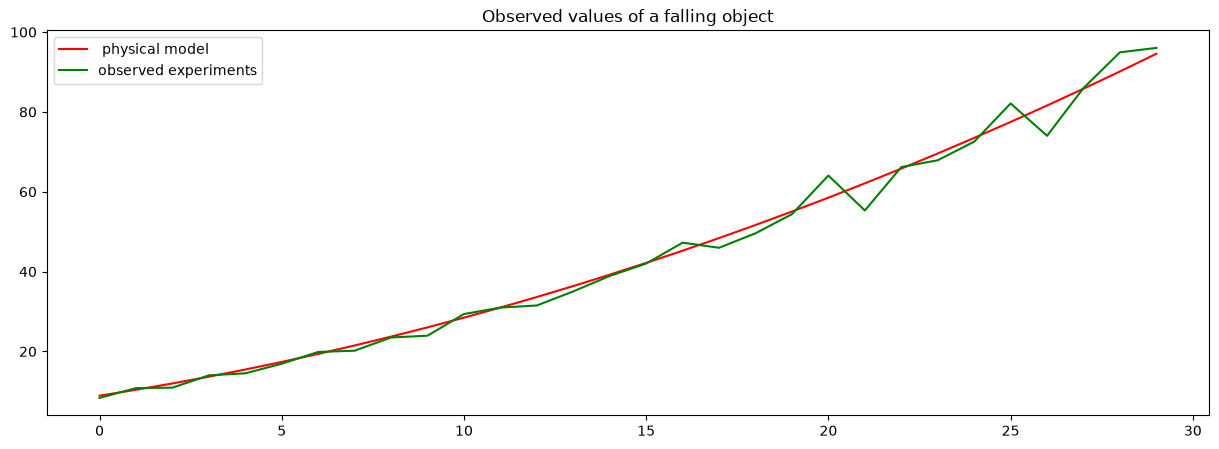

53.924833580526816


In [8]:
# Just for getting a nice wide picture.
plt.rcParams["figure.figsize"] = (15,5)

# Consider this real model. It models the distance of an object moving at an acceleration g at a given time t.
# s (t) = g * t**2 /2  + v0 * t
# MEASURED QUANTITIES: s: distance(output)   t: time (input);  
# PARAMETERS TO FIND:    v0: initial speed;  g: gravitational constant (falling object)

# Generating data (this is somewhat artificial, only
# for testing built-in minimization procedures):
# Given uniform times:  
t_all = np.linspace(1,4,30)  
# We know the real values of parameters:
v0 = 4 
g = 9.82
# With these, the analytic result for the distance
s_analytical = g * t_all**2 / 2  + v0 * t_all
# OK, we will randomize the data by
# giving this random  multiplyer vector:
r_mult = np.random.normal(1,0.05, 30) # normal ( mean, standard dev, size)
# Compute pointwise multiplication
# Assume that this is the observed data for distance:
s_obs = r_mult * s_analytical # off by 5% from true measures!

plt.plot(s_analytical, color ='red', label= ' physical model')
plt.plot(s_obs, color = 'green', label = 'observed experiments')
plt.title("Observed values of a falling object")
plt.legend()
plt.show()

# In which norm should we measure their deviation?
# First in the Manhattan norm : 

# abs ( g * t_all[0]**2 /2  + v0 * t_all[0] - s_obs [0] )  + abs (g * t_all[1]**2 /2  + v0 * t_all[1] - s_obs [1])  +
#  ...   + abs (g * t_all[29]**2 /2  + v0 * t_all[29] - s_obs [29])  
print(np.linalg.norm(s_analytical - s_obs, 1))

In [9]:
# Define the loss as a function.
# Now we fix the above generated data and the observation times.

# some initial parameters.  Recall true parameters g = 9.82. and v_0 = 4.
param_init = np.array([10,3]) # parameters: g, v_0.

def loss_g_v(param):
    g = param[0]
    v_0 = param[1]
    #sum (abs (param[0] * t_all**2 /2 + param[1] * t_all - s_obs)) can be also used
    return  np.linalg.norm( g * t_all ** 2 /2 + v_0 * t_all - s_obs , 1 ) 
    

# We can minimize it with for the parameters
#minimize tries  different values for the parameters g, v_0 in loss_g_v (g,v_0) to find the smallest one.
#Nelder-mead method is a gradient free method.
res = minimize(loss_g_v, param_init, method='nelder-mead',
               options={'xatol': 1e-8, 'disp': True}) #tolerance for stopping the algorithm, disp = True prints convergence info.
print(res.x) #.x returns the values where the loss function is minimal.


# Try to start from far.
print("Starting from further distance:")
param_init = np.array([15,9]) # parameters: g, v_0.
res = minimize(loss_g_v, param_init, method='nelder-mead',
               options={'xatol': 1e-8, 'disp': True}) #tolerance for stopping the algorithm, disp = True prints convergence info.
print(res.x) #.x returns the values where the loss function is minimal.

# Same story but now we use the usual L2-norm squared.
print("Redefining the loss function using the L2 norm:")
param_init = np.array([10,5]) # parameters: g, v_0.

def loss_g_v(param):
    g = param[0]
    v_0 = param[1]
    #sum (abs (param[0] * t_all**2 /2 + param[1] * t_all - s_obs)) can be also used
    return  np.linalg.norm( g * t_all ** 2 /2 + v_0 * t_all - s_obs , 2 ) ** 2
res = minimize(loss_g_v, param_init, method='nelder-mead',
               options={'xatol': 1e-8, 'disp': True}) #tolerance for stopping the algorithm, disp = True prints convergence info.
print(res.x) #.x returns the values where the loss function is minimal.

# Now  using the usual max-norm.
param_init = np.array([10,5]) # parameters: g, v_0.
print('Redefining the loss function using the max-norm:')
def loss_g_v(param):
    g = param[0]
    v_0 = param[1]
    #sum (abs (param[0] * t_all**2 /2 + param[1] * t_all - s_obs)) can be also used
    return  np.linalg.norm( g * t_all ** 2 /2 + v_0 * t_all - s_obs , np.inf ) 
res = minimize(loss_g_v, param_init, method='nelder-mead',
               options={'xatol': 1e-8, 'disp': True}) #tolerance for stopping the algorithm, disp = True prints convergence info.
print(res.x) #.x returns the values where the loss function is minimal.


Optimization terminated successfully.
         Current function value: 51.411786
         Iterations: 110
         Function evaluations: 210
[10.12250209  3.46967246]
Starting from further distance:
Optimization terminated successfully.
         Current function value: 51.411786
         Iterations: 115
         Function evaluations: 217
[10.12250209  3.46967246]
Redefining the loss function using the L2 norm:
Optimization terminated successfully.
         Current function value: 207.588512
         Iterations: 74
         Function evaluations: 153
[10.26436506  3.20551753]
Redefining the loss function using the max-norm:
Optimization terminated successfully.
         Current function value: 6.291294
         Iterations: 94
         Function evaluations: 182
[9.48022021 4.27635441]


# GENERATING RANDOM DATA FOR AN INFECTIOUS DISEASE AND FITTING PARAMETERS

[0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.
 0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.
 0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.
 0.    0.    0.    0.001 0.001 0.001 0.002 0.004 0.006 0.01  0.016 0.025
 0.039 0.06  0.09  0.132 0.186 0.254 0.333 0.419 0.506 0.59  0.665 0.731
 0.786 0.831 0.867 0.896 0.918 0.936 0.95  0.961 0.97  0.976 0.982 0.986
 0.989 0.991 0.993 0.995 0.996 0.997 0.998 0.998 0.998 0.999 0.999 0.999
 0.999 1.    1.    1.    1.    1.    1.    1.    1.    1.    1.    1.
 1.    1.    1.    1.    1.   ]


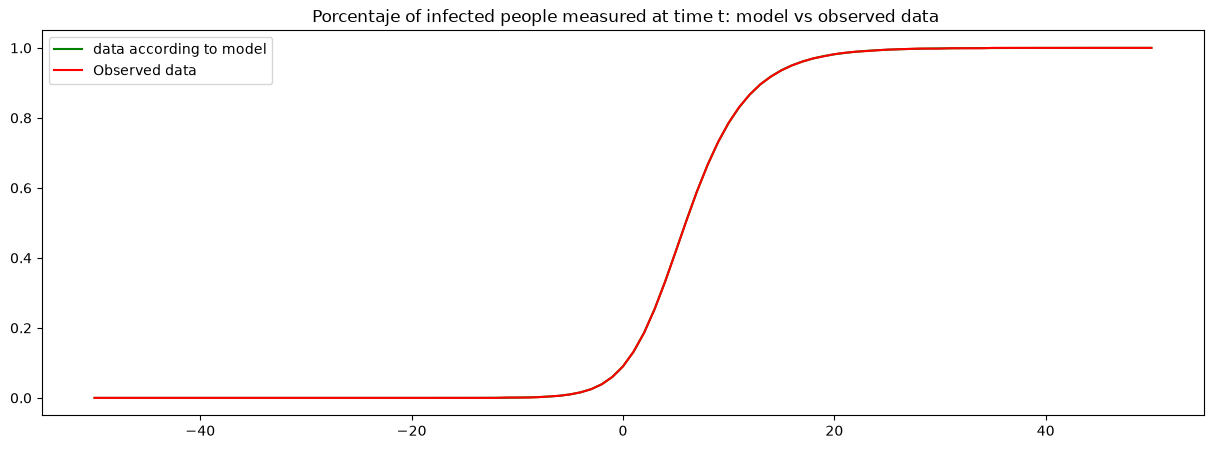

In [10]:
plt.rcParams["figure.figsize"] = (15,5)

# The times when we measure the percentage of the infected people.
# Day 0 is the day the infection breaks.
days = np.linspace(-50,50, 101)

# This is considered the real data with the real parameters (for testing
# purposes, we construct it).
# We are using the following model: 
# inf (n)  =  1/(1 + np.exp(-n/A+B)+np.exp(-n/C+D))
#  for some parameters A = 4, B =1 , C = 2, D =2.
real_f_w = 1/(1+np.exp(-days/4+1) + np.exp(-days/2+2))

# Let us plot it.
plt.plot(days, real_f_w, color ='green', label = "data according to model")

# Now we did not directly randomize the data but just take 
# its 3-digit neighbor instead.
# We are simulating lack of precision in measurements (this will make very little difference in our actual measurements, see e.g graph)
# 1000 * real_f_w moves the decimal point 3 steps to the right, 
# then np.round () rounds to the closest integer, and then we divide 1000 to return to our original scale.
rand_f_w = np.round(1000*real_f_w)/1000
rand_f_w.shape    
print(rand_f_w)
plt.plot(days, rand_f_w, color ='red', label ='Observed data ')   
plt.title(" Porcentaje of infected people measured at time t: model vs observed data")
plt.legend() 
plt.show()
# In real life, our observations would be for example: 300 out of 1000 people infected. We prefer porcentages
#  since normalized data is better for us. So we rather not multiply it to have integers. 




In [11]:
# We have now the previous randomized (observation) data 
# and try to find the parameters A, B, C and D such that 
# the function 
##      inf (n)  =  1/(1 + np.exp(-n/A+B)+np.exp(-n/C+D))
# fits our observation as good as possible.

# Here the possible input - values:  day -50, 0, 1, ..., 50  
# where 0 is the day where the rapid growth of the infection starts.
# The model-given output: 
# 1/(1+np.exp(-50/A+B)+np.exp(-50/C+D)), 1/(1+np.exp(-49/A+B)+np.exp(-49/C+D)), 
# ... , 1/(1+np.exp(50/A+B)+np.exp(50/C+D)).

# This should be compared with real observation
# rand_f_w [0], rand_f_w [1], ..., rand_f_w [101].


# We measure their deviation again in the Manhattan norm : 

# abs (1/(1+np.exp(-50/A+B)+np.exp(-50/C+D)) - rand_f_w [0])  + abs (A/(B+np.exp(-2/C+D)) - rand_f_w [1]) +
#  ...   + abs (A/(B+np.exp(-1000/C+D)) - rand_f_w [999])


## Goal, finding parameters [A, B, C, D]. 
# Initial guess:
param_init = [3.5, 1.5, 2.1, 2.2]

# define a function which will give the loss for a fixed parameter-vector
def loss_inf_est(param):
    A = param[0]
    B = param[1]
    C = param[2]
    D = param[3]
    return sum (abs (1/(1 + np.exp(-days/A + B)+np.exp(-days/C + D)) - rand_f_w))

print(f"Loss function evaluated at the true parameters gives: {loss_inf_est(np.array([4, 1, 2, 2]))}")
print(f"Loss function evaluated at different parameters [1,3,4,1]: {loss_inf_est(np.array([1, 3, 4, 1]))}")

# We can minimize it to find the parameters:
print(f"Minimizing loss function with initial guess {param_init}")
res = minimize(loss_inf_est, param_init, method='nelder-mead',
               options={'xatol': 1e-8, 'disp': True})
print(res.x)

# Try to run it from different initial parameters; e.g. from this one:   param = [5, 3, 2, 0]
# We can minimize it to find the parameters:
print("Same test with initial guess [5,3,2,0]:")
res = minimize(loss_inf_est, np.array([5,3,2,0]), method='nelder-mead',
               options={'xatol': 1e-8, 'disp': True})
print(res.x)

# We cannot compute gradients with respect to the parameters: absolute value function is not differentiable

Loss function evaluated at the true parameters gives: 0.014936048000176174
Loss function evaluated at different parameters [1,3,4,1]: 0.8471668849265247
Minimizing loss function with initial guess [3.5, 1.5, 2.1, 2.2]
Optimization terminated successfully.
         Current function value: 0.013313
         Iterations: 368
         Function evaluations: 629
[4.03232508 0.96595278 2.0150742  2.01333236]
Same test with initial guess [5,3,2,0]:
Optimization terminated successfully.
         Current function value: 0.289873
         Iterations: 425
         Function evaluations: 745
[ 3.02896381  2.00039538  1.13766395 -0.00749678]


In [13]:
# Try a similar optimization using square loss function
print("Using the standard Euclidean norm squared in the loss function:")
def loss_inf_est(param):
    A = param[0]
    B = param[1]
    C = param[2]
    D = param[3]
    return sum ((1/(1 + np.exp(-days/A + B)+np.exp(-days/C + D)) - rand_f_w) ** 2)
res = minimize(loss_inf_est, param_init, method = 'nelder-mead', options = {'xatol': 1e-8, 'disp':True})
print(res.x)

# and also the maximum-distance.

Using the standard Euclidean norm squared in the loss function:
Optimization terminated successfully.
         Current function value: 0.000004
         Iterations: 297
         Function evaluations: 505
[4.02099918 0.97731668 2.01127993 2.00861934]


In [14]:
# Could we use this method to find the largest eigenvalue of a symmetric matrix?
# for symmetric matrices, we know that \lambda_max = max_{||x||=1} x.T * Ax. We can turn
#this problem into a minimization one by changing x.TAx to -x.T *Ax. 
A =np.random.rand(10,10)
A_sym = 0.5 * (A + A.T)
lambdas, eigv = np.linalg.eigh(A_sym)
lambda_max = lambdas[-1]
eigv_max = eigv[:,-1]
print(f"let us check the eigenvector corresponding to the largest eigenvalue:{eigv_max}")
print(f"And the largest eigenvalue: {lambda_max}")
#Then, our loss function can be -x.T * Ax. Here, the "parameters" are x = (x_1,..., x_n). But wait!
# We have the extra constraint that ||x|| =1. How can we addd this to the loss function? 
# Using a constrained minimization method, e.g SLSQP (Sequential least square programming )

def loss_x (x):
    return(-x.T @ (A_sym @ x)) 
def penalty (x):
    return (np.linalg.norm(x)-1)**2 # we want values away from 1 to be more punishable (they make loss f. larger)
initial_guess = np.ones(10,) 
eta_g = 1000
res = minimize (loss_x, initial_guess,method='SLSQP', constraints = {'type': 'eq', 'fun': penalty},options ={'xatol': 1e-8, 'disp':True})
print("The approximation of the eigenvector:")
print(res.x)
print("The approximation of the largest eigenvalue:")
print((res.x).T @ A_sym @ res.x)

let us check the eigenvector corresponding to the largest eigenvalue:[-0.33043239 -0.29537197 -0.2681573  -0.33227712 -0.35059694 -0.40801043
 -0.26711504 -0.26748134 -0.29959409 -0.31497516]
And the largest eigenvalue: 4.923487966765031
Optimization terminated successfully    (Exit mode 0)
            Current function value: -4.923494036162065
            Iterations: 43
            Function evaluations: 506
            Gradient evaluations: 43
The approximation of the eigenvector:
[0.33041571 0.29545498 0.26831723 0.33226144 0.35049583 0.40770297
 0.26726307 0.26763269 0.29964995 0.31500076]
The approximation of the largest eigenvalue:
4.923494036162065


/var/folders/vn/gynv2n1d1h7d9npnn9zf_js80000gn/T/ipykernel_76335/2849367621.py:21: OptimizeWarning: Unknown solver options: xatol
  res = minimize (loss_x, initial_guess,method='SLSQP', constraints = {'type': 'eq', 'fun': penalty},options ={'xatol': 1e-8, 'disp':True})
